# Quantum GANs to Generate Handwritten Digits

This notebook is an adaptation of a PennyLane tutorial. It has been modified to be fully functional in Google Colab.

This notebook demonstrates a **Quantum Generative Adversarial Network (QGAN)** used to generate handwritten digits of seven.
It includes:

- A detailed introduction to the classical theory of GANs.
- An in-depth discussion of the quantum method, including the circuit architecture.
- Visualisation of the quantum circuit using **Qiskit**.
- Plots of the generator and discriminator training loss.
- Visualisation of generated images at different stages of training.

## Classical GANs

A **Generative Adversarial Network (GAN)** is a machine learning model for unsupervised learning that learns to mimic a data distribution. A GAN consists of two competing components: a **Generator (G)** and a **Discriminator (D)**.

- **Generator G(θ):** produces samples that resemble real data.
- **Discriminator D(φ):** distinguishes real data from generated samples.

We can describe this interaction between the generator and the classifier in terms of *game theory*.
Game theory is a branch of mathematics that studies interactions between decision-makers, or 'players,'
whose choices mutually affect each other's outcomes, or 'payoffs.'
Players have a set of choices called 'strategies' that they can make, and we assume that they will always choose the strategy that maximises their own payoff or utility.

A fundamental outcome in any case is the *Nash Equilibrium*.
This is the set of strategies chosen by each player where nobody can unilaterally change their strategy to make themselves better off.

We can think of a GAN as consisting of two players in the generator and the discriminator.
As mentioned above the goal of the generator is to produce samples that the discriminator thinks are real.
Therefore the 'payoff' for $G$ is the probability that $D$ will misclassify one of its samples; during training the generator will try to maximise this probability.
On the other hand, the payoff for the discriminator is the probability that it classifies its input correctly as real or fake.

Note that the higher the payoff for the generator, the lower the payoff for the discriminator, and vice versa.
This turns the game into a *zero-sum game*, because the two players' payoffs always sum to 0.

We can formulate this idea more rigorously as follows.
Tthe training dataset represents samples drawn from some
unknown data distribution $P_{data},$ and the generator has the job of
trying to capture this distribution. The generator, $G,$ starts from
some initial latent distribution, $P_z,$ and maps it to $P_g = G(P_z).$
The best solution would be for $P_g = P_{data}.$ However, this point is
rarely achieved in practice apart from in the most simple tasks.

The discriminator spits out a number, $D(x)$, that represents how likely it thinks the data is real.
If $x$ is sampled from $p_{\text{data}}$, this number should be close to $1$.
If $x=G(z)$ where $z$ is sampled from $P_z$, then $D(x)$ should be close to $0$---or, equivalently, $1-D(x)$ should be close to $1$.

This can be encapsulated in the function
$$\begin{aligned}
\begin{align}
V(D,G) &= \mathbb{E}_{\boldsymbol{x}\sim p_{data}}[\log D(\boldsymbol{x})] \\
    & ~~ + \mathbb{E}_{\boldsymbol{z}\sim p_{\boldsymbol{z}}}[\log(1 - D(G(\boldsymbol{z}))]
\end{align}
\end{aligned}$$
-   $\boldsymbol{x}:$ real data sample
-   $\boldsymbol{z}:$ latent vector
-   $D(\boldsymbol{x}):$ probability of the discriminator classifying
    real data as real
-   $G(\boldsymbol{z}):$ fake data
-   $D(G(\boldsymbol{z})):$ probability of discriminator classifying
    fake data as real

The discriminator wants to maximise this function; if it correctly classifies its input as real or fake, both expected values are close to $0$.
If the discriminator is awful at separating truth from fiction, both terms will be very negative (this is why we take the expected value of the *logarithm* of the output of $D$ and $G$).
But this is exactly what the generator wants---to produce outputs that the discriminator cannot tell are fake.
So the generator wants exactly the opposite: to minimise $V(D,G)$.

This allows us to summarise the dynamics of the game by the min-max optimisaton problem
$$
\begin{align}
\min_G \max_D V(D,G) &= \mathbb{E}_{\boldsymbol{x}\sim p_{data}}[\log D(\boldsymbol{x})] \\
    & ~~ + \mathbb{E}_{\boldsymbol{z}\sim p_{\boldsymbol{z}}}[\log(1 - D(G(\boldsymbol{z}))].
\end{align}
$$

What is the Nash equilibrium of this game?
Remember that the Nash equilibrium is the set of outcomes at which no player can improve their position unilaterally.
In this case it would be the point at which the discriminator is guessing randomly---that is, $D(x)=0.5$ regardless of $x$.
This means that the generator is producing fake output indistinguishable from real output, so it cannot improve its payoff---but neither can the discriminator, because if it did, the generator would get better at creating fake samples.

In practice, the two networks are trained iteratively, each with a
separate loss function to be minimised,

$$L_D = -[y \cdot \log(D(x)) + (1-y)\cdot \log(1-D(G(z)))]$$

$$L_G = [(1-y) \cdot \log(1-D(G(z)))]$$

where $y$ is a binary label for real ($y=1$) or fake ($y=0$) data. In
practice, generator training is shown to be more stable when made to
maximise $\log(D(G(z)))$ instead of minimising $\log(1-D(G(z))).$ Hence,
the generator loss function to be minimised becomes,

$$L_G = -[(1-y) \cdot \log(D(G(z)))]$$

<br>

## Quantum GANs
**Quantum GANs (QGANs)** extend this idea using quantum circuits. One effective approach is the **patch method**, implemented in PennyLane [1]:

- The **patch method** divides the image generation task across multiple small **quantum sub-generators**, $G^{(i)}$, where each generates a small patch of the final image.
- The full image is constructed by concatenating all patches.
- This approach reduces the number of qubits needed per generator and allows parallel or sequential execution on a quantum device.

<br>

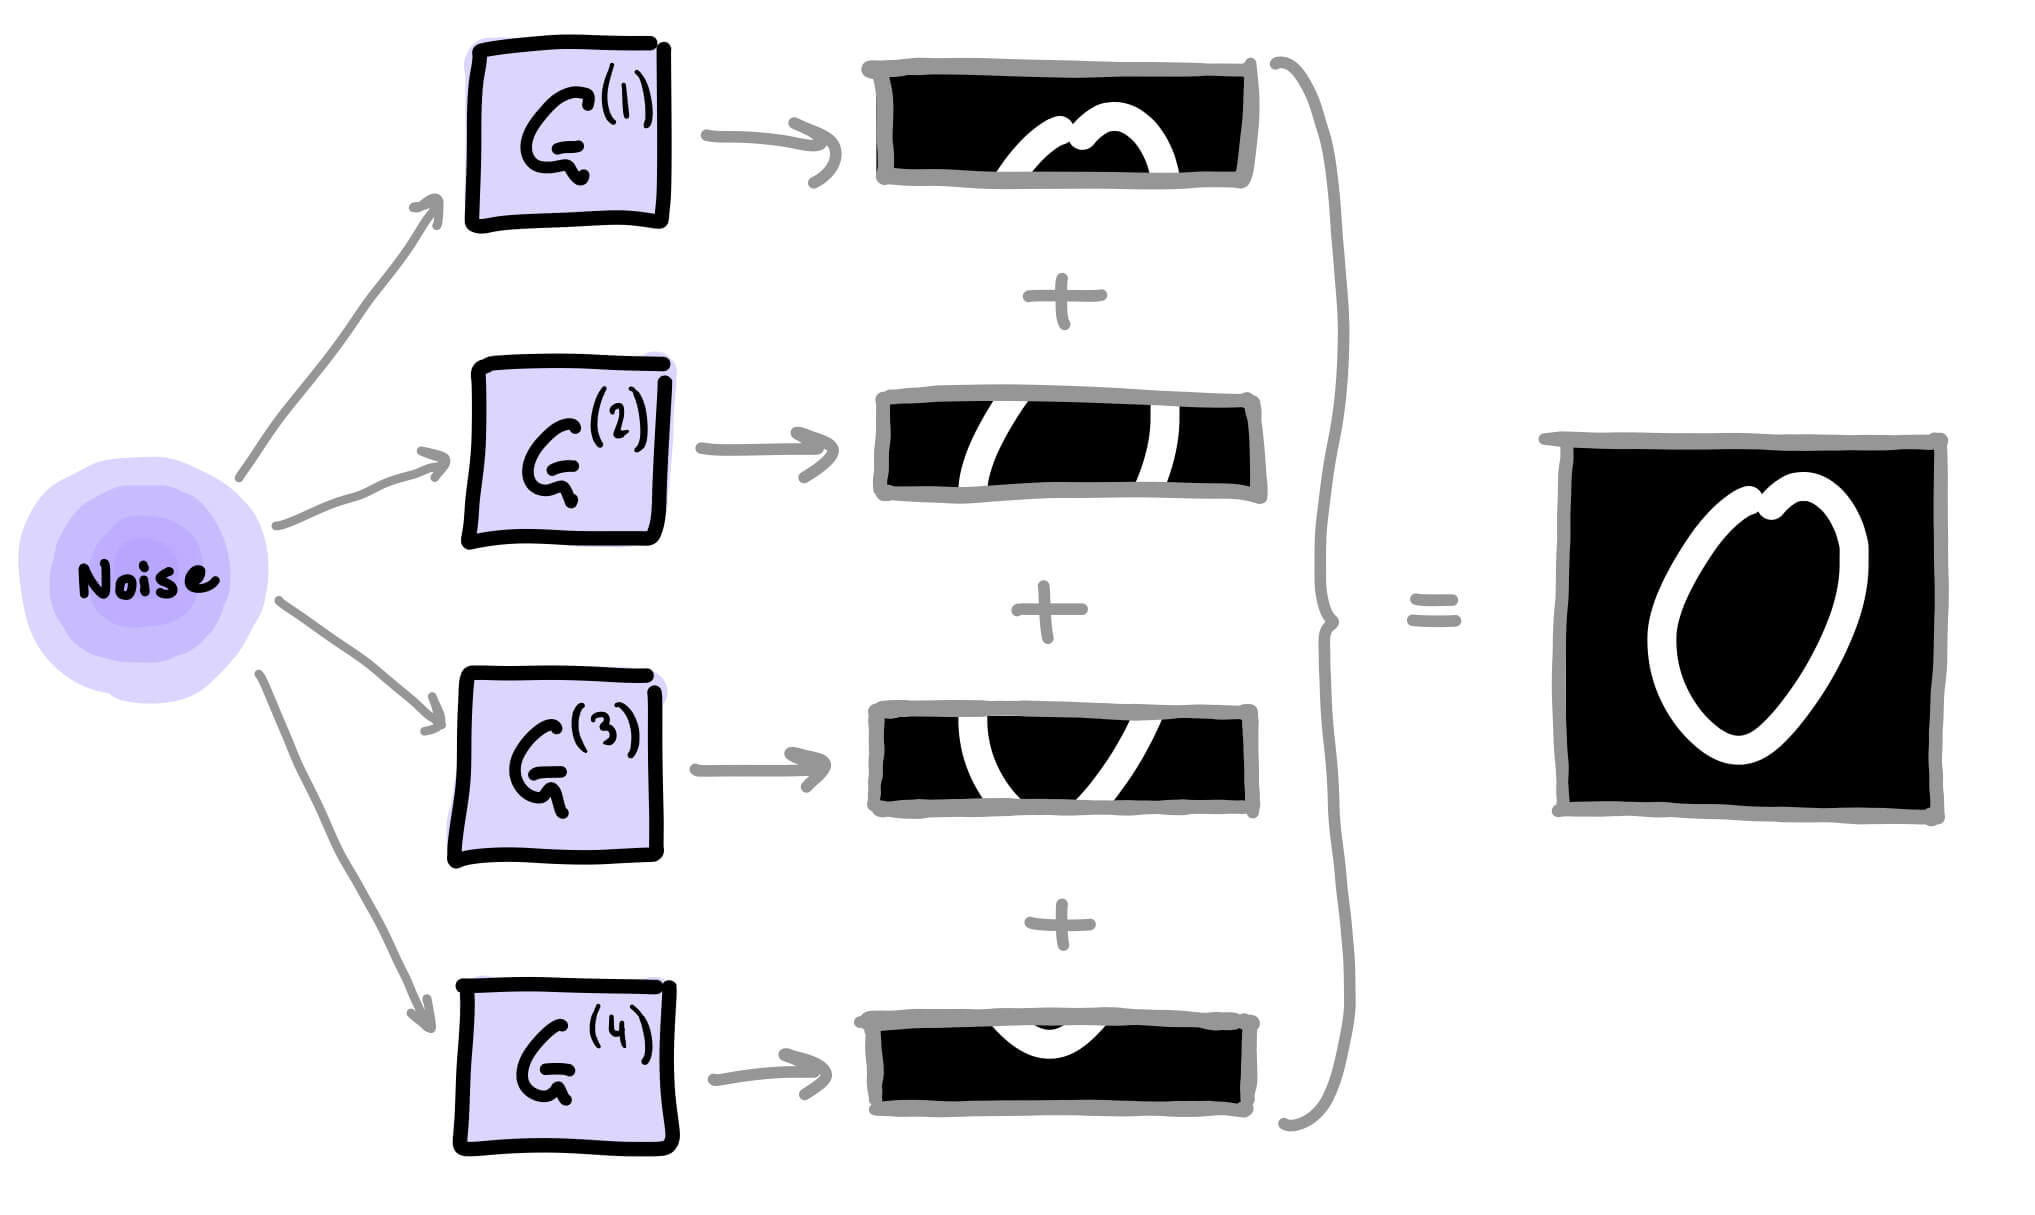


Basic diagram of the patch method in quantum GANs. [1]

<br>

The discriminator can remain classical or also be implemented as a quantum circuit. Training proceeds similarly to classical GANs: the discriminator learns to distinguish real from fake, and each quantum generator is trained to fool the discriminator, with the patch structure allowing scalable generation of larger images from limited quantum resources.

This method is particularly suited for situations with limited qubits, making fully quantum image generation feasible.


## Why QGANs?

- Quantum Generative Adversarial Networks (QGANs) leverage quantum phenomena like superposition and entanglement to offer advantages over classical GANs.

- They can represent complex probability distributions more efficiently, enabling more realistic data generation, and may accelerate training through quantum parallelism. [2]

- QGANs can handle high-dimensional data for tasks like image synthesis or molecular modeling [2], and recent architectures improve noise resilience [3].

- They are especially promising in specialized domains such as drug discovery [4], though practical use is still limited by current quantum hardware.

## Setup and module imports

First, we install the necessary libraries and download the dataset.

In [ ]:
# Install dependencies first:  pip install -r ../requirements.txt

# Download the UCI Optical Recognition of Handwritten Digits training set (8x8 images)
import os, urllib.request
if not os.path.exists("optdigits.tra"):
    urllib.request.urlretrieve(
        "https://archive.ics.uci.edu/ml/machine-learning-databases/optdigits/optdigits.tra",
        "optdigits.tra")
# Library imports
import math
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import pennylane as qml
from qiskit import QuantumCircuit
from qiskit.visualization import plot_circuit_layout

# Pytorch imports
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader

# Set the random seed for reproducibility
seed = 42
torch.manual_seed(seed)
np.random.seed(seed)
random.seed(seed)

%matplotlib inline

## Data Loading

We'll use a small dataset of handwritten sevens. The custom `DigitsDataset` class below filters the dataset to only include images of the digit '7'.

In [ ]:
class DigitsDataset(Dataset):
    """Pytorch dataloader for the Optical Recognition of Handwritten Digits Data Set"""

    def __init__(self, csv_file, label=7, transform=None):
        """
        Args:
            csv_file (string): Path to the csv file with annotations.
            label (int): The digit label to filter for.
            transform (callable, optional): Optional transform to be applied on a sample.
        """
        self.csv_file = csv_file
        self.transform = transform
        self.df = self.filter_by_label(label)

    def filter_by_label(self, label):
        # Use pandas to return a dataframe of only the specified label
        df = pd.read_csv(self.csv_file, header=None)
        df = df.loc[df.iloc[:, -1] == label]
        return df

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        if torch.is_tensor(idx):
            idx = idx.tolist()

        # The dataset values range from 0-16, so we divide by 16 to normalize.
        image = self.df.iloc[idx, :-1].values / 16
        image = image.astype(np.float32).reshape(8, 8)

        if self.transform:
            image = self.transform(image)

        # Return image and a dummy label
        return image, 7

In [ ]:
image_size = 8  # Height / width of the square images
batch_size = 1

transform = transforms.Compose([transforms.ToTensor()])
dataset = DigitsDataset(csv_file="optdigits.tra", transform=transform)
dataloader = torch.utils.data.DataLoader(
    dataset, batch_size=batch_size, shuffle=True, drop_last=True
)

Let's visualize some of the real data.

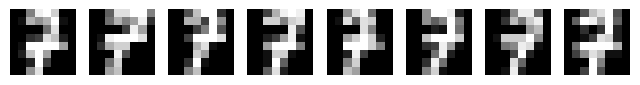

In [ ]:
plt.figure(figsize=(8,2))

for i in range(8):
    image = dataset[i][0].reshape(image_size,image_size)
    plt.subplot(1,8,i+1)
    plt.axis('off')
    plt.imshow(image.numpy(), cmap='gray')

plt.show()

## Implementing the Discriminator

The discriminator is a classical, fully connected neural network with two hidden layers. Its job is to distinguish real images from fake ones generated by the quantum generator.

In [ ]:
class Discriminator(nn.Module):
    """Fully connected classical discriminator"""

    def __init__(self):
        super().__init__()

        self.model = nn.Sequential(
            # Inputs to first hidden layer (64 -> 64)
            nn.Linear(image_size * image_size, 64),
            nn.ReLU(),
            # First hidden layer (64 -> 16)
            nn.Linear(64, 16),
            nn.ReLU(),
            # Second hidden layer (16 -> output)
            nn.Linear(16, 1),
            nn.Sigmoid(),
        )

    def forward(self, x):
        return self.model(x)

## Implementing the Generator
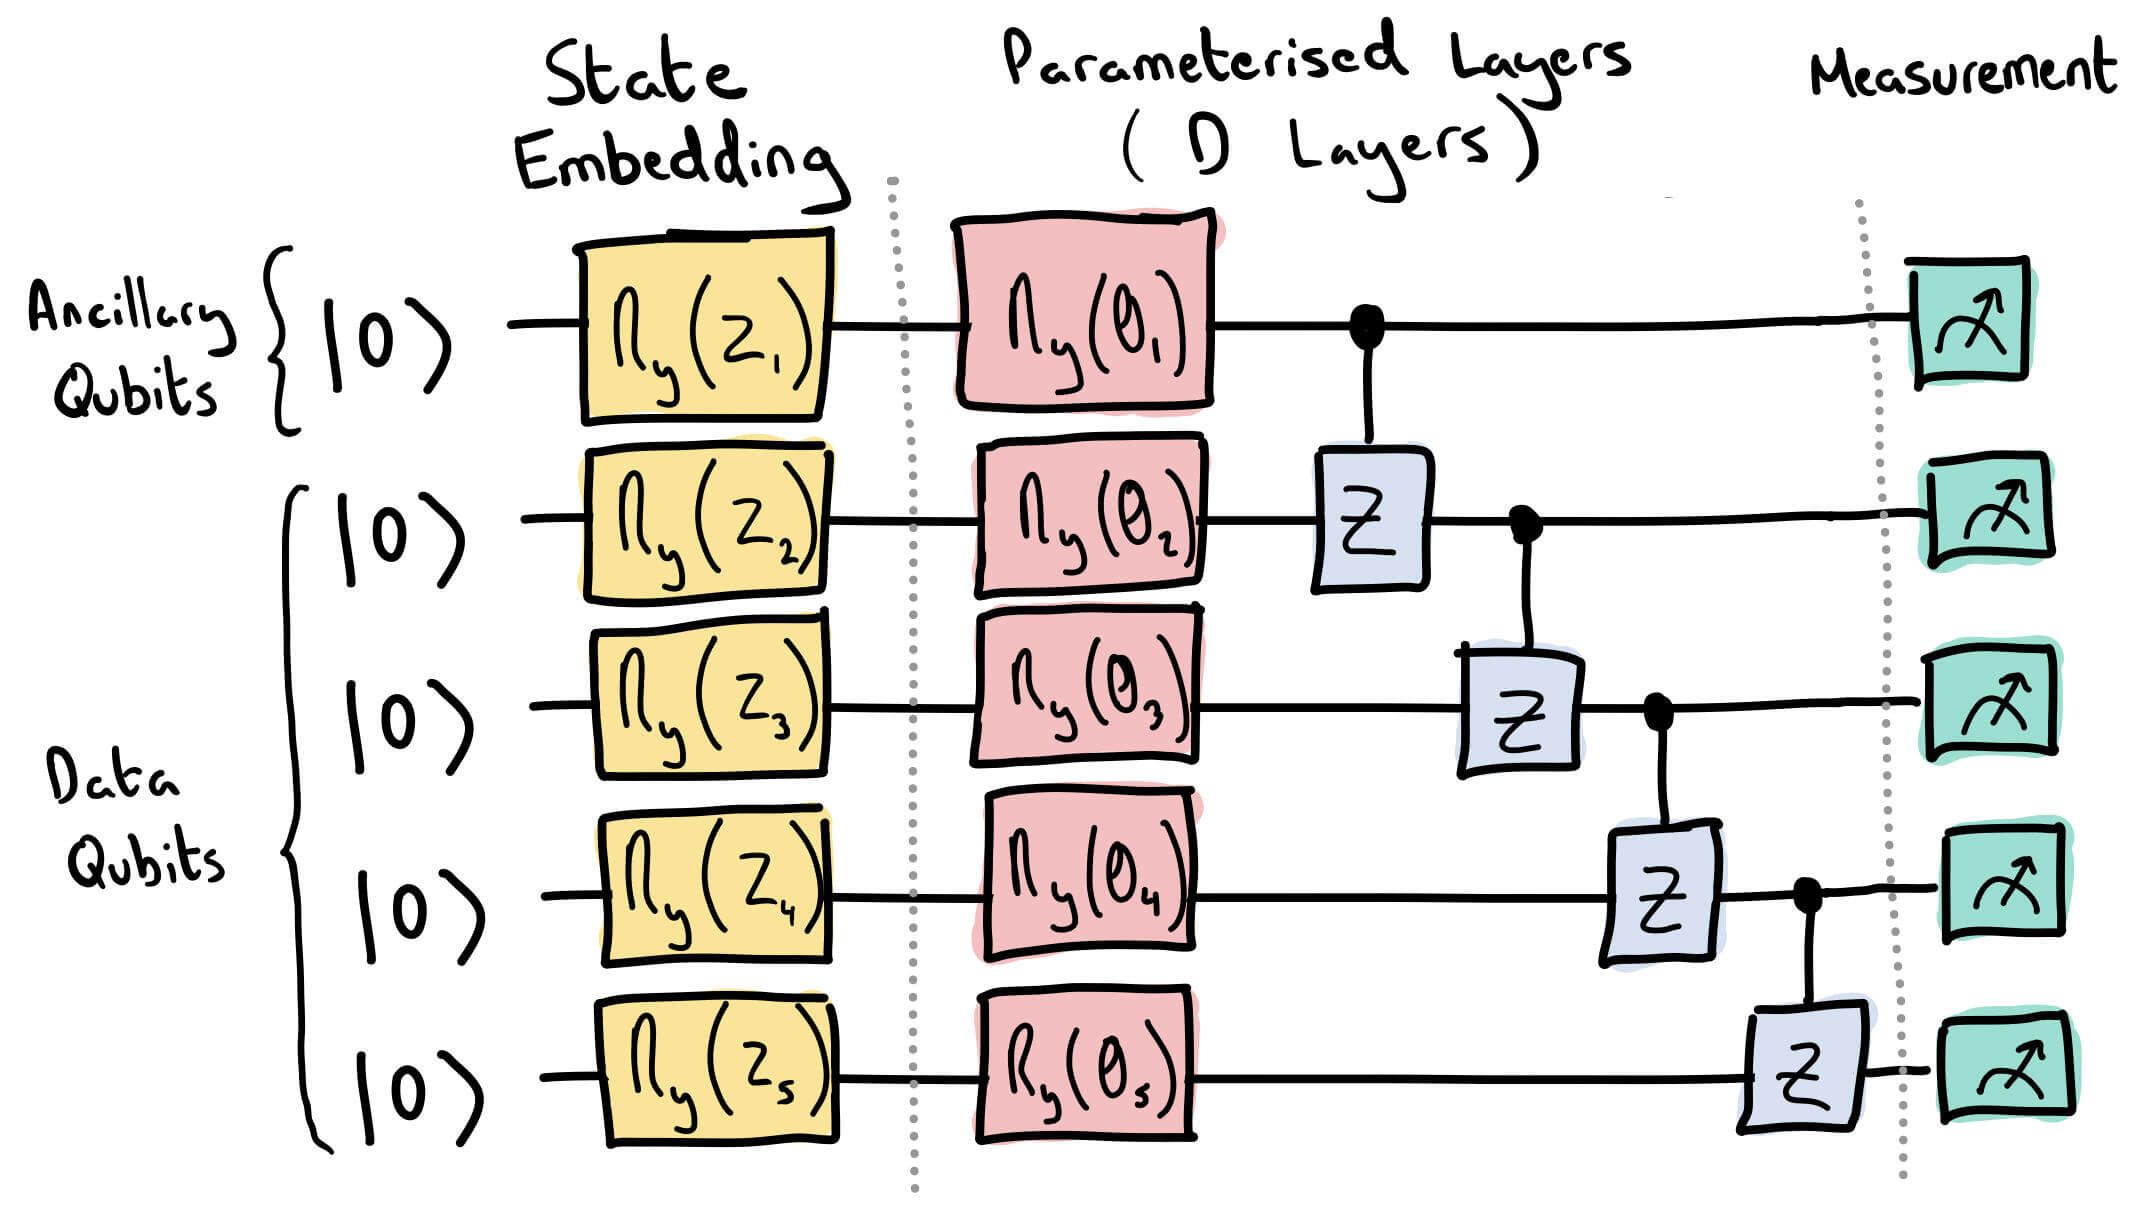

Basic quantum circuit diagram of the generator. [1]
<br>
<br>
The quantum generator consists of $(N_G)$ sub-generators, each with \(N\) qubits and the same circuit architecture. The generative process has four stages:

1. **State Embedding:**  
Sample a latent vector $(\boldsymbol{z} \in [0, \pi/2)^N)$ and embed it into each sub-generator using RY gates.

2. **Parameterised Layers:**  
Apply \(D\) layers of parameterised RY gates followed by controlled-Z gates. The overall unitary for a sub-generator is

\begin{equation}
|\Psi(\boldsymbol{z})\rangle = U_G(\theta) |\boldsymbol{z}\rangle
\end{equation}

3. **Non-Linear Transform:**  
Use ancillary qubits and partial measurement $\Pi$ to induce a non-linear transformation. Tracing out the ancillas gives the post-measurement state

\begin{equation}
\rho(\boldsymbol{z}) =
\frac{\mathrm{Tr}_{\mathcal{A}} \Big( \Pi \otimes \mathbb{I} \, |\Psi(\boldsymbol{z})\rangle \langle \Psi(\boldsymbol{z})| \Big)}
{\mathrm{Tr} \Big( \Pi \otimes \mathbb{I} \, |\Psi(\boldsymbol{z})\rangle \langle \Psi(\boldsymbol{z})| \Big)}
=
\frac{\mathrm{Tr}_{\mathcal{A}} \Big( \Pi \otimes \mathbb{I} \, |\Psi(\boldsymbol{z})\rangle \langle \Psi(\boldsymbol{z})| \Big)}
{\langle \Psi(\boldsymbol{z})| \Pi \otimes \mathbb{I} |\Psi(\boldsymbol{z})\rangle}
\end{equation}

Measuring $\rho(\boldsymbol{z})$ in the computational basis gives the sub-generator output:

\begin{equation}
\boldsymbol{g}^{(i)} = [P(0), P(1), \dots, P(2^{N-N_A}-1)]
\end{equation}

4. **Post-Processing:**  
Scale each sub-generator output to produce pixel intensities:

\begin{equation}
\boldsymbol{\tilde{x}}^{(i)} = \frac{\boldsymbol{g}^{(i)}}{\max_k \boldsymbol{g}_k^{(i)}}
\end{equation}

The final image is obtained by concatenating all patches:

\begin{equation}
\boldsymbol{\tilde{x}} = [\boldsymbol{\tilde{x}}^{(1)}, \dots, \boldsymbol{\tilde{x}}^{(N_G)}]
\end{equation}




In [ ]:
# Quantum variables
n_qubits = 5  # Total number of qubits
n_a_qubits = 1  # Number of ancillary qubits
q_depth = 6  # Depth of the quantum circuit
n_generators = 4  # Number of sub-generators for the patch method

Now we define the quantum device. We'll use PennyLane's `lightning.qubit` simulator for performance. The code will automatically use a GPU if one is available in the Colab runtime.

In [ ]:
# Quantum simulator
dev = qml.device("lightning.qubit", wires=n_qubits)
# Enable CUDA device if available
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

Next, we define the quantum circuit and measurement process.

In [ ]:
@qml.qnode(dev, diff_method="parameter-shift")
def quantum_circuit(noise, weights):
    weights = weights.reshape(q_depth, n_qubits)

    # Initialise latent vectors
    for i in range(n_qubits):
        qml.RY(noise[i], wires=i)

    # Repeated layers
    for i in range(q_depth):
        # Parameterised layer
        for y in range(n_qubits):
            qml.RY(weights[i][y], wires=y)

        # Control Z gates
        for y in range(n_qubits - 1):
            qml.CZ(wires=[y, y + 1])

    return qml.probs(wires=list(range(n_qubits)))

def partial_measure(noise, weights):
    # Non-linear Transform
    probs = quantum_circuit(noise, weights)
    probsgiven0 = probs[: (2 ** (n_qubits - n_a_qubits))]
    probsgiven0 /= torch.sum(probs)

    # Post-Processing
    probsgiven = probsgiven0 / torch.max(probsgiven0)
    return probsgiven

Now we create the full quantum generator class, which combines the outputs of the sub-generators.

In [ ]:
class PatchQuantumGenerator(nn.Module):
    """Quantum generator class for the patch method"""

    def __init__(self, n_generators, q_delta=1):
        """
        Args:
            n_generators (int): Number of sub-generators to be used in the patch method.
            q_delta (float, optional): Spread of the random distribution for parameter initialisation.
        """
        super().__init__()

        # Each sub-generator has its own set of quantum parameters
        self.q_params = nn.ParameterList(
            [
                nn.Parameter(q_delta * torch.rand(q_depth * n_qubits), requires_grad=True)
                for _ in range(n_generators)
            ]
        )
        self.n_generators = n_generators

    def forward(self, x):
        # Size of each sub-generator output
        patch_size = 2 ** (n_qubits - n_a_qubits)

        # Create a tensor to store the batch of images
        images = torch.Tensor(x.size(0), 0).to(device)

        # Iterate over all sub-generators
        for params in self.q_params:
            # Create a tensor to store the batch of patches from a single sub-generator
            patches = torch.Tensor(0, patch_size).to(device)
            for elem in x:
                q_out = partial_measure(elem, params).float().unsqueeze(0)
                patches = torch.cat((patches, q_out))

            # Concatenate the patches to create the images
            images = torch.cat((images, patches), 1)

        return images

## Training

Now we can set up the models, optimizers, and loss function to start the training process. The loop will run for `num_iter` iterations, alternating between training the discriminator and the generator.

In [ ]:
lrG = 0.3  # Learning rate for the generator
lrD = 0.01  # Learning rate for the discriminator
num_iter = 1000  # Number of training iterations
discriminator = Discriminator().to(device)
generator = PatchQuantumGenerator(n_generators).to(device)

# Lists to store metrics for plotting
G_losses = []
D_losses = []
D_real_accuracies = []
D_fake_accuracies = []

# Binary cross entropy loss
criterion = nn.BCELoss()

# Optimizers
optD = optim.SGD(discriminator.parameters(), lr=lrD)
optG = optim.SGD(generator.parameters(), lr=lrG)

real_labels = torch.full((batch_size,), 1.0, dtype=torch.float, device=device)
fake_labels = torch.full((batch_size,), 0.0, dtype=torch.float, device=device)

# Fixed noise allows us to visually track the generated images throughout training
fixed_noise = torch.rand(8, n_qubits, device=device) * math.pi / 2

# Iteration counter
counter = 0

# Collect images for plotting later
results = []

while True:
    for i, (data, _) in enumerate(dataloader):

        # ----------------- #
        #  Train Discriminator
        # ----------------- #
        real_data = data.reshape(-1, image_size * image_size).to(device)

        # Noise following a uniform distribution in range [0, pi/2)
        noise = torch.rand(batch_size, n_qubits, device=device) * math.pi / 2
        fake_data = generator(noise)

        # Train with real data
        discriminator.zero_grad()
        outD_real = discriminator(real_data).view(-1)
        errD_real = criterion(outD_real, real_labels)
        errD_real.backward()

        # Train with fake data
        outD_fake = discriminator(fake_data.detach()).view(-1)
        errD_fake = criterion(outD_fake, fake_labels)
        errD_fake.backward()

        errD = errD_real + errD_fake
        optD.step()

        # ----------------- #
        #  Train Generator
        # ----------------- #
        generator.zero_grad()
        outD_fake = discriminator(fake_data).view(-1)
        # We use real_labels here as a trick to fool the discriminator
        errG = criterion(outD_fake, real_labels)
        errG.backward()
        optG.step()

        counter += 1

        # Store metrics every 10 iterations to match your print frequency
        if counter % 10 == 0:
            # Append loss values
            G_losses.append(errG.item())
            D_losses.append(errD.item())

            # Calculate and append discriminator accuracies
            # Accuracy on real images
            real_preds = (outD_real >= 0.5).float()
            real_acc = (real_preds == real_labels).float().mean().item()
            D_real_accuracies.append(real_acc)

            # Accuracy on fake images
            fake_preds = (outD_fake < 0.5).float() # Note: we use < 0.5 for fake
            fake_acc = (fake_preds == real_labels).float().mean().item() # Comparing to all 1s after flipping
            D_fake_accuracies.append(fake_acc)

        # Show loss values
        if counter % 10 == 0:
            print(f'Iteration: {counter}, Discriminator Loss: {errD.item():0.3f}, Generator Loss: {errG.item():0.3f}')
            test_images = generator(fixed_noise).view(8,1,image_size,image_size).cpu().detach()

            # Save images every 50 iterations
            if counter % 50 == 0:
                results.append(test_images)

        if counter == num_iter:
            break
    if counter == num_iter:
        break

Iteration: 10, Discriminator Loss: 1.384, Generator Loss: 0.596
Iteration: 20, Discriminator Loss: 1.378, Generator Loss: 0.601
Iteration: 30, Discriminator Loss: 1.348, Generator Loss: 0.627
Iteration: 40, Discriminator Loss: 1.366, Generator Loss: 0.614
Iteration: 50, Discriminator Loss: 1.309, Generator Loss: 0.658
Iteration: 60, Discriminator Loss: 1.285, Generator Loss: 0.663
Iteration: 70, Discriminator Loss: 1.288, Generator Loss: 0.662
Iteration: 80, Discriminator Loss: 1.296, Generator Loss: 0.645
Iteration: 90, Discriminator Loss: 1.274, Generator Loss: 0.651
Iteration: 100, Discriminator Loss: 1.295, Generator Loss: 0.637
Iteration: 110, Discriminator Loss: 1.221, Generator Loss: 0.707
Iteration: 120, Discriminator Loss: 1.248, Generator Loss: 0.670
Iteration: 130, Discriminator Loss: 1.233, Generator Loss: 0.676
Iteration: 140, Discriminator Loss: 1.226, Generator Loss: 0.669
Iteration: 150, Discriminator Loss: 1.359, Generator Loss: 0.593
Iteration: 160, Discriminator Loss

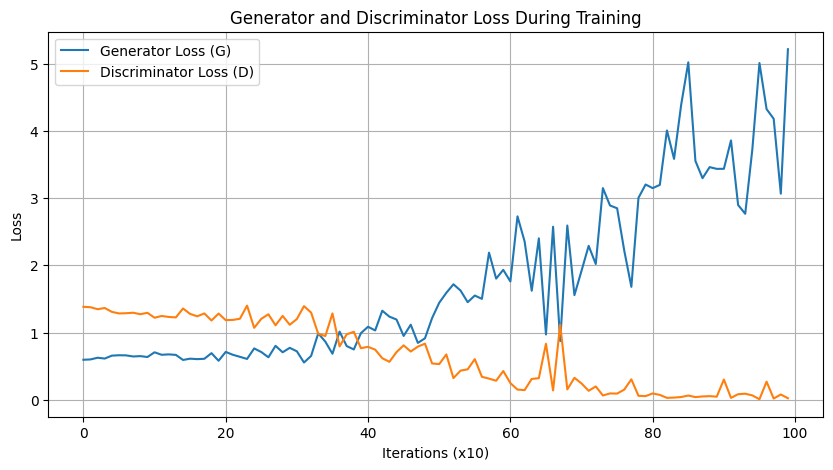

In [ ]:
# Loss plots
plt.figure(figsize=(10, 5))
plt.title("Generator and Discriminator Loss During Training")
plt.plot(G_losses, label="Generator Loss (G)")
plt.plot(D_losses, label="Discriminator Loss (D)")
plt.xlabel("Iterations (x10)")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

## Results

Let's plot the images generated by our quantum generator at different stages of the training process. You should see the noisy, random images from early iterations gradually begin to resemble the digit '7'.

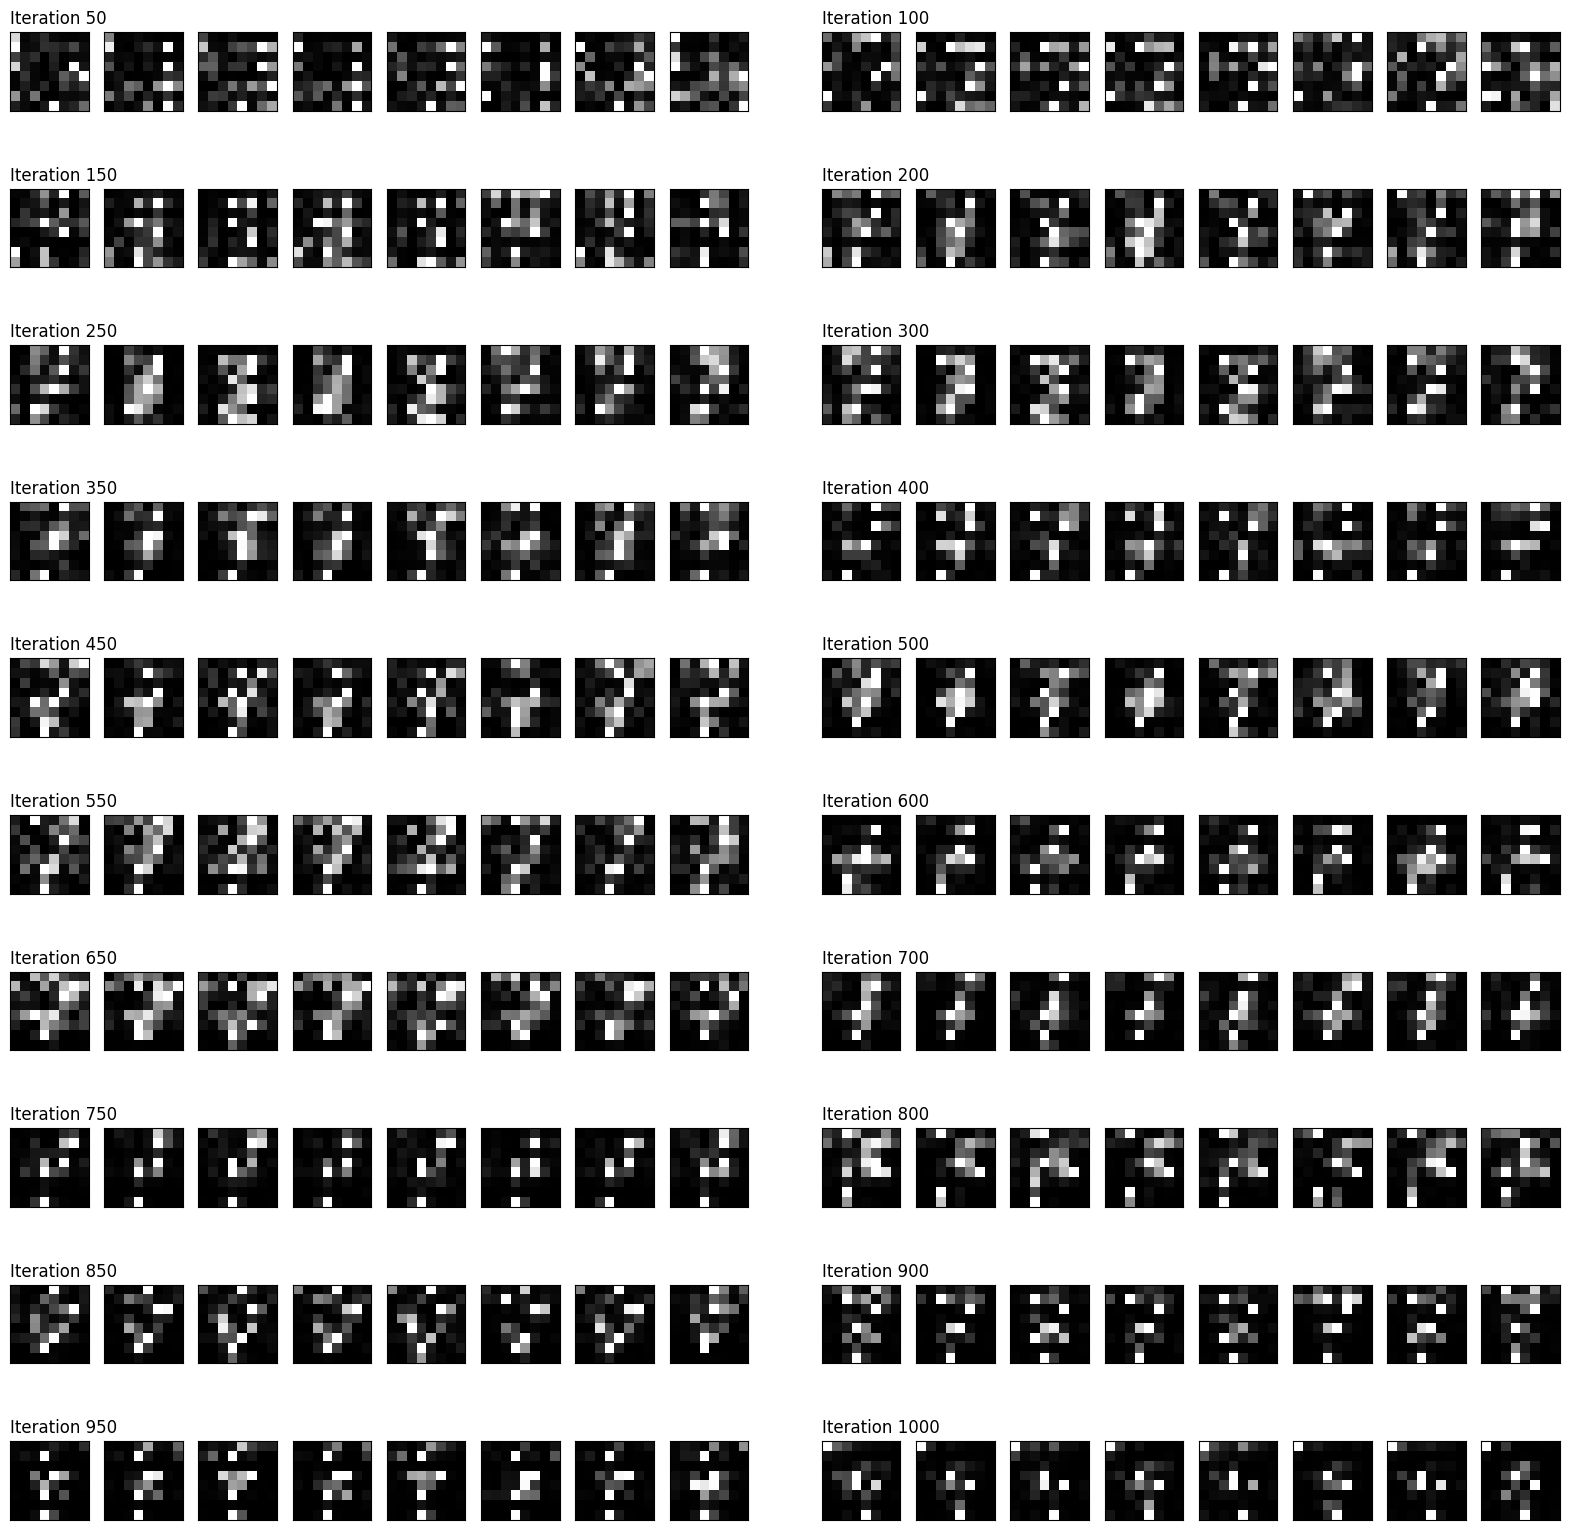

In [ ]:
fig = plt.figure(figsize=(20, 20))
outer = gridspec.GridSpec(10, 2, wspace=0.1)

for i, images in enumerate(results):
    inner = gridspec.GridSpecFromSubplotSpec(1, images.size(0),
                    subplot_spec=outer[i])

    images = torch.squeeze(images, dim=1)
    for j, im in enumerate(images):

        ax = plt.Subplot(fig, inner[j])
        ax.imshow(im.numpy(), cmap="gray")
        ax.set_xticks([])
        ax.set_yticks([])
        if j==0:
            ax.set_title(f'Iteration {50+i*50}', loc='left')
        fig.add_subplot(ax)

plt.show()

## Visualising the circuit

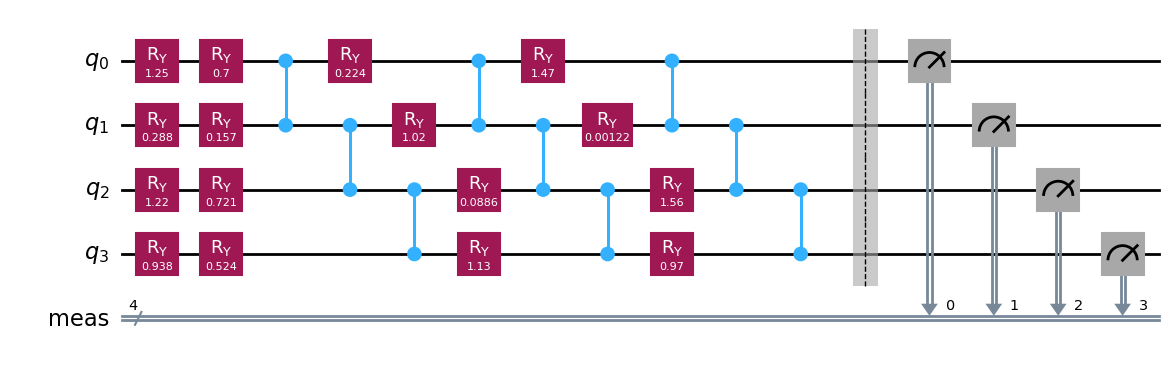

In [ ]:
# Parameters (match your setup)
n_qubits = 4      # total number of qubits
q_depth = 3       # circuit depth
noise = np.random.uniform(0, np.pi/2, n_qubits)     # latent vector
weights = np.random.uniform(0, np.pi/2, (q_depth, n_qubits))  # random weights

# Build the circuit
qc = QuantumCircuit(n_qubits)

# Initial RY rotations for noise embedding
for i in range(n_qubits):
    qc.ry(noise[i], i)

# Repeated parameterised layers
for i in range(q_depth):
    # Parameterised RY layer
    for y in range(n_qubits):
        qc.ry(weights[i][y], y)

    # CZ entangling layer
    for y in range(n_qubits - 1):
        qc.cz(y, y + 1)

# Draw the circuit
qc.measure_all()
qc.draw("mpl")  # or qc.draw("text") for ASCII style

## References

[1] J. Ellis, “Quantum GANs | PennyLane Demos,” PennyLane, Jan. 31, 2022. [Online]. Available: https://pennylane.ai/qml/demos/tutorial_quantum_gans/

[2] M. Islam, S. Turkeli, F. Ozaydin, “A Survey of Quantum Generative Adversarial Networks: Architectures, Use Cases, and Real-World Implementations,” arXiv preprint arXiv:2506.18002, 22 June 2025.
arXiv

[3] Y. Tian, C. Tian, Z. Fan, M. Fu, …, H. Ma, “Quantum generative adversarial network with automated noise suppression mechanism based on WGAN-GP,” EPJ Quantum Technology, vol. 12, art. no. 80, 23 June 2025.
SpringerOpen

[4] Po-Yu Kao, Ya-Chu Yang, Wei-Yin Chiang, Jen-Yueh Hsiao, Yudong Cao, Alex Aliper, Feng Ren, Alán Aspuru-Guzik, Alex Zhavoronkov, Min-Hsiu Hsieh, Yen-Chu Lin, “Exploring the Advantages of Quantum Generative Adversarial Networks in Generative Chemistry”, Journal of Chemical Information and Modeling, vol. 63, no. 11, pp. 3307–3318, May 12, 2023. doi: 10.1021/acs.jcim.3c00562


## AI Acknowledgment
This code was developed with the assistance of **ChatGPT (OpenAI)** and **Gemini (Google DeepMind)**. These tools were used to support code generation, debugging, and documentation, ensuring clarity and efficiency in implementation.